In [ ]:
import os
import gc
import pandas as pd
from collections import defaultdict
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.cm as cm 
import seaborn as sns
from typing import List, Tuple, Dict, Any
from PIL import Image
from torchvision import datasets, transforms
from torchvision.io.image import read_image
import torch
import torchvision
import torch.nn as nn 
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import Dataset, DataLoader, random_split, SubsetRandomSampler, ConcatDataset, Subset

from torchcam.utils import overlay_mask
from torchcam.methods import SmoothGradCAMpp, SSCAM, LayerCAM, GradCAM, GradCAMpp, XGradCAM
from torchvision.transforms.functional import normalize, to_pil_image

import cv2
import re

import pandas as pd
import numpy as np
from tqdm import tqdm
from sklearn.metrics import accuracy_score, mean_absolute_error, r2_score, mean_absolute_percentage_error, root_mean_squared_error
from sklearn.model_selection import KFold
import scipy.stats as stats

from helper_fns.remove_baseline import remove_baseline
from helper_fns.compute_noise_level import estimate_noise
from scipy.signal import savgol_filter, medfilt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.manifold import TSNE

In [2]:
import warnings
warnings.filterwarnings('ignore')

# Sensor SNR Compute

## Functions

In [3]:
def extract_numbers_and_follwing_letter(s):
    # Regex to find all numbers including integers and floating-point numbers
    pattern = r'\d+\.?\d*[a-zA-Z]'
    return re.findall(pattern, s)

def group_by_letter(matches):
    # Dictionary to group numbers by their ending letter
    grouped = defaultdict(list)
    
    for match in matches:
        ending_letter = match[-1]
        grouped[ending_letter].append(match)
    
    return dict(grouped)

def extract_params_from_filename(filename):
    params = []
    #use regex to extract number from the filename
    numbers = extract_numbers_and_follwing_letter(filename)
    #replace 1mA with 1000uA
    numbers = [str(int(i[0])*1000) +'u' if i.endswith('m') else i for i in numbers]
    #group numbers by the ending letter
    dicts = group_by_letter(numbers)
    if len(dicts['M']) > 1:
        for i in range(len(dicts['M'])):
            params.append(dicts['M'][i] + '_'+dicts['u'][i]+'_'+dicts['s'][i])
    elif len(dicts['M']) == 1 and len(dicts['u']) > 1:
        for i in range(len(dicts['u'])):
            params.append(dicts['M'][0] + '_'+dicts['u'][i]+'_'+dicts['s'][i])
    elif len(dicts['M']) == 1 and len(dicts['u']) == 1:
        for i in range(len(dicts['s'])):
            params.append(dicts['M'][0] + '_'+dicts['u'][0]+'_'+dicts['s'][i])
    return params

def find_cycles(data, min_len=50):
    """Return list of (on_idx, off_idx) for real exposure cycles."""
    transitions = []
    for i in range(1, len(data)):
        pc, cc = data[i - 1][2], data[i][2]
        if pc == 0 and cc > 0:
            transitions.append(('ON',  i))
        elif pc > 0 and cc == 0:
            transitions.append(('OFF', i))

    cycles = []
    i = 0
    while i < len(transitions) - 1:
        if transitions[i][0] == 'ON' and transitions[i + 1][0] == 'OFF':
            on, off = transitions[i][1], transitions[i + 1][1]
            if off - on >= min_len:
                cycles.append((on, off))
            i += 2
        else:
            i += 1
    return cycles

def load_sheet_data(ws):
    """Return list of (time, resistance, conc) from a sheet."""
    data = []
    for row in ws.iterrows():
        t    = row[1].iloc[1]
        r    = row[1].iloc[2]
        conc = row[1].iloc[6]
        if t is not None and r is not None and isinstance(conc, (int, float)):
            data.append((t, float(r), float(conc)))
    return np.array(data)

def response(vals):
    response = sum(vals[-10:])/10
    return response

def base_response(vals):
    n = len(vals)
    if n == 0:
        return 0.0
    return sum([vals[i] for i in range(0, 10)]) / 10
    
def mean_std(vals):
    n = len(vals)
    if n == 0:
        return 0.0, 0.0
    m = sum(vals) / n
    std = np.array(vals).std()
    return m, std

def _jitter_median(y, kernel=101):
    """
    Replaces each sample with the median of its neighbours.
    Removes isolated spikes without smearing edges.
    Kernel must be odd.
    """
    kernel = kernel if kernel % 2 == 1 else kernel + 1
    return medfilt(y, kernel_size=kernel)

In [4]:
def GPUClean():
   # Clear the GPU cache|
    torch.cuda.empty_cache()

    # Force garbage collection
    gc.collect()

    # Check memory usage
    print(f"Memory Allocated: {torch.cuda.memory_allocated() / 1024 ** 2} MB")
    print(f"Memory Reserved: {torch.cuda.memory_reserved() / 1024 ** 2} MB")

def snrToClass(snr):
    if float(snr) < 5.0:
        return 0
    elif 5.0 < float(snr) < 10.0:
        return 1
    elif 10.0 < float(snr) < 20.0:
        return 2
    elif float(snr) > 20.0:
        return 3


def getFabParams(original_label):
    splitted = original_label.split('-')
    mol = splitted[0][:-1]
    curr = splitted[1][:-2]
    time = splitted[2][:-1]
    return np.array([float(mol), float(curr), float(time)])

## Compute SNR

In [5]:
#base_response_path ="E:\ZnO_sensing_optimisation\Sensor-optimize-new-replicate\Sensor Responses\\"
base_response_path ="E:\ZnO_sensing_optimisation\sensor-param-opt\\new_sensor_responses\\"
dfs_full = {}
for filename in os.listdir(base_response_path):
    if filename.endswith('xlsx'):
        params = extract_params_from_filename(filename)
        df = pd.read_excel(base_response_path+filename, sheet_name=0)
        dfs_full[params[0]] = df

print(len(dfs_full.keys()))

72


In [6]:
results = []
for param, signal_df in dfs_full.items():
    
    param_list = param.split("_")
    sol_con = param_list[0][:-1]
    current = param_list[1][:-1]
    time = param_list[2][:-1]

    signal = load_sheet_data(signal_df)
    cycles = find_cycles(signal)
    flat_signal, _ = remove_baseline(signal[:, 1], method = 'als')

    for c_num, (on, off) in enumerate(cycles, 1):

            if c_num == 1:
                bl_start   = max(0, on - 40)
                baseline_R = [signal[j][1] for j in range(10, bl_start) if signal[j][2] == 0]
                baseline_C = [flat_signal[j] for j in range(10, bl_start) if signal[j][2] == 0]
            else:
                baseline_C = [flat_signal[j] for j in range(on, on+40)]
            exp_C      = [flat_signal[j] for j in range(on, off)]
            #if not baseline_R or not exp_R:
            #    continue
            mean_conc          = sum(signal[j][2] for j in range(on, off)) / (off - on)
            R_base             = base_response(baseline_C) # baseline removed base response
            _, sigma_base      = mean_std(baseline_R) # sigma from original response
            #noise_overall, _   = estimate_noise(signal[:,1])
            R_exp              = response(exp_C)
            delta_R            = abs(R_exp - R_base)
            snr_lin = delta_R / sigma_base if sigma_base > 0 else float('inf')
            
            scaled_baseline = MinMaxScaler().fit_transform(np.array(baseline_R).reshape(-1, 1)).flatten()
            _, sigma_scaled = mean_std(scaled_baseline)
            
            

            results.append([sol_con, current, time, c_num, 
                            round(mean_conc, 4), round(R_base, 4), 
                            round(R_exp, 4), round(delta_R, 4), 
                            round(sigma_base, 4), round(sigma_scaled, 4),
                             round(snr_lin, 4)])

print(len(results))

2160


In [7]:
snr_df = pd.DataFrame(results, columns=['sol_con', 'current', 'time', 'cycle_no', 'mean_conc', 'base_r', 'response_r', 'delta_r', 'sigma_base',  "sigma_scaled", 'snr_lin' ])
sensor_snr_df = snr_df.groupby(['sol_con', 'current', 'time']).median().reset_index()
#remove outlier
print(sensor_snr_df.snr_lin.max())
sensor_snr_df = sensor_snr_df[sensor_snr_df['snr_lin'] < sensor_snr_df['snr_lin'].max()]
print(sensor_snr_df.snr_lin.max())
snr_df.to_csv('snr_no_outlier.csv', index = False)

156.22930000000002
67.18915


In [ ]:
#snr_df = pd.read_csv('snr_no_outlier.csv')
#sensor_snr_df = snr_df.groupby(['sol_con', 'current', 'time']).median().reset_index()


In [8]:
custom_label_clean = {}
for _, row in sensor_snr_df.iterrows():
    name = str(row.sol_con)+'M-' + str(row.current) + 'uA-' + str(row.time) + 's'
    custom_label_clean[name] = float(row.snr_lin)#[row.snr, row.response_time]

magnification = '500x'
custom_label = {}
for _, row in sensor_snr_df.iterrows():
    name = str(row.sol_con)+'M-' + str(row.current) + 'uA-' + str(row.time) + 's-'+ magnification
    custom_label[name] = float(row.snr_lin)#[row.snr, row.response_time]

# Prepare SEM

##  Functions

In [98]:
def find_all_image_paths(base_dir: str, image_extensions: List[str] = ['.jpg', '.jpeg', '.png', '.tiff']) -> List[Path]:
    """
    Recursively finds all image file paths in all subdirectories 
    of the given base directory.

    The group identifier for cross-validation is the immediate parent directory 
    of the image file.

    Args:
        base_dir (str): The root directory to start the search from.
        image_extensions (List[str]): List of file extensions to search for.

    Returns:
        List[Path]: A list of pathlib.Path objects for all found image files.
    """
    base_path = Path(base_dir)
    if not base_path.is_dir():
        raise FileNotFoundError(f"Directory not found: {base_dir}")
        
    all_files: List[Path] = []
    
    # Use glob to find all files recursively matching the extensions
    for ext in image_extensions:
        # **/*.ext finds all files ending in 'ext' in all subdirectories
        all_files.extend(base_path.glob(f"**/*{ext}"))
        
    # Filter to ensure paths are actual files and have a valid parent (subdirectory)
    all_files = [
        p for p in all_files 
        if p.is_file() and p.parent != base_path # Exclude files directly in base_dir
    ]
    
    if not all_files:
        print(f"Warning: No images found with extensions {image_extensions} in subdirectories of {base_dir}")
        
    return all_files

def create_balanced_group_folds(all_file_paths: List[Path], n_splits: int = 4) -> List[Tuple[np.ndarray, np.ndarray]]:
    """
    Generates train/test indices such that every subdirectory (group) 
    has at least one sample in the test set and at least one sample in the 
    training set for every fold.

    Args:
        all_file_paths (List[Path]): The list of all image paths in the dataset.
        n_splits (int): The number of folds (K). Must be <= min_images_per_group.

    Returns:
        List[Tuple[np.ndarray, np.ndarray]]: A list of (train_indices, test_indices) 
                                             tuples for each fold.
    """
    if n_splits < 2:
        raise ValueError("n_splits must be at least 2 to ensure both train/test representation.")

    # 1. Map global indices to group-local indices
    # Structure: {group_name: {global_index: local_index}}
    group_map: Dict[str, List[int]] = {}
    
    # Store the actual indices for each group
    group_indices: Dict[str, List[int]] = {}

    for global_idx, path in enumerate(all_file_paths):
        # The parent directory name is the group identifier (e.g., 'group_01')
        group_name = path.parent.name
        
        if group_name not in group_indices:
            group_indices[group_name] = []
        
        group_indices[group_name].append(global_idx)

    # 2. Split indices within each group using KFold
    all_fold_test_indices: List[List[int]] = [[] for _ in range(n_splits)]
    
    # KFold object to split indices locally
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    for group_name, indices in group_indices.items():
        if len(indices) < n_splits:
             # This is a critical check for the constraint: If a group has 
             # fewer samples than folds, some folds will have an empty test set 
             # for this group. This is unavoidable if n_splits > min_images.
             print(f"Warning: Group '{group_name}' has only {len(indices)} samples, but {n_splits} splits requested.")
        
        # Generate the local splits for the current group's indices
        local_splits = list(kf.split(indices))
        
        for fold_k in range(n_splits):
            # The test indices for fold_k are the *values* in the indices list
            # corresponding to the local test IDs.
            local_test_ids = local_splits[fold_k][1]
            global_test_indices = [indices[local_id] for local_id in local_test_ids]
            
            # Aggregate test indices for this global fold
            all_fold_test_indices[fold_k].extend(global_test_indices)
            
    # 3. Finalize global train/test index arrays
    all_indices = np.arange(len(all_file_paths))
    final_splits = []
    
    for test_indices_list in all_fold_test_indices:
        test_indices = np.array(test_indices_list, dtype=int)
        
        # Calculate train indices as the complement of test indices
        train_mask = np.ones(len(all_file_paths), dtype=bool)
        train_mask[test_indices] = False
        train_indices = all_indices[train_mask]
        
        final_splits.append((train_indices, test_indices))

    return final_splits, group_indices # Return the splits and the group mapping for verification

# Function to save tensor images as PNG files
def save_transformed_image(tensor, filename):
    # Undo the normalization to convert the tensor back to an image
    unnormalize = transforms.Compose([
        #transforms.Normalize(mean=[-2.118, -2.036, -1.804], std=[4.367, 4.464, 4.444]),  # Reversing normalization
        transforms.ToPILImage()  # Convert tensor to PIL image
    ])
    
    image = unnormalize(tensor)  # Convert tensor to PIL image
    image.save(filename)   


def getFabParams(original_label):
    splitted = original_label.split('-')
    mol = splitted[0][:-1]
    curr = splitted[1][:-2]
    time = splitted[2][:-1]
    return np.array([float(mol), float(curr), float(time)])

class PreprocessDataset(Dataset):
    def __init__(self, file_paths, transform=None, targets=None):
        """
        Args:
            root_dir (str): Directory with all the images.
            transform (callable, optional): Optional transform to be applied on a sample.
            targets (list): List of target values for each image.
        """
        
        self.file_paths = file_paths
        self.dataset = datasets.ImageFolder(root=self.file_paths)
        self.transform = transform
        self.class_to_custom_label = {cls: snrToClass(targets[cls]) for cls in self.dataset.classes}# 1 for good performance 0 for bad
        self.class_to_param = {cls: getFabParams(cls) for cls in self.dataset.classes}
        self.targets = targets

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img, original_label = self.dataset[idx]
        fab_param = self.class_to_param[self.dataset.classes[original_label]]

        custom_label = self.class_to_custom_label[self.dataset.classes[original_label]]
        snr_label = self.targets.get(self.dataset.classes[original_label])
        
        if self.transform:
            img = self.transform(img)

        return img, fab_param, custom_label, snr_label

def slice_image_into_patches(image_tensor, patch_size=32):
    """
    Slices an image tensor into non-overlapping patches of size `patch_size x patch_size`.
    
    Args:
        image_tensor (torch.Tensor): Input image tensor of shape (H, W) or (C, H, W)
        patch_size (int): The size of each patch (default is 32x32)

    Returns:
        patches (torch.Tensor): Tensor of shape (num_patches_y, num_patches_x, C, patch_size, patch_size)
                                or (num_patches_y, num_patches_x, patch_size, patch_size) for grayscale
    """
    # Check if the image has channel dimensions (C, H, W) or (H, W)
    if image_tensor.dim() == 2:
        # Add a channel dimension for grayscale images
        image_tensor = image_tensor.unsqueeze(0)
    
    # Get image dimensions
    C, H, W = image_tensor.shape
    
    # Ensure that the image dimensions are divisible by the patch size
    assert H % patch_size == 0 and W % patch_size == 0, "Image dimensions must be divisible by the patch size."
    
    # Reshape the tensor to create patches
    patches = image_tensor.unfold(1, patch_size, patch_size).unfold(2, patch_size, patch_size)
    
    # Move the patch dimensions to the front
    patches = patches.permute(1, 2, 0, 3, 4)
    
    return patches


class SliceImageIntoPatches(object):
    def __init__(self, patch_size=32):
        self.patch_size = patch_size

    def __call__(self, img):
        """
        Args:
            img (PIL.Image or torch.Tensor): Image to be sliced.
        
        Returns:
            List of torch.Tensors: List of image patches as tensors.
        """
        # Convert PIL image to a tensor if necessary
        if isinstance(img, Image.Image):
            img = transforms.ToTensor()(img)

        # Check if the image has channel dimensions (C, H, W) or (H, W)
        if img.dim() == 2:
            # Add a channel dimension for grayscale images
            img = img.unsqueeze(0)
        
        C, H, W = img.shape
        
        # Ensure that the image dimensions are divisible by the patch size
        assert H % self.patch_size == 0 and W % self.patch_size == 0, "Image dimensions must be divisible by the patch size."


        # Reshape the tensor to create patches
        patches = img.unfold(1, self.patch_size, self.patch_size).unfold(2, self.patch_size, self.patch_size)
        
        # Move the patch dimensions to the front
        patches = patches.permute(1, 2, 0, 3, 4)
        # Calculate the number of patches
        #num_patches_h = H // self.patch_size
        #num_patches_w = W // self.patch_size
        
        #patches = []
        #for i in range(num_patches_h):
        #    for j in range(num_patches_w):
        #        patch = img[:, i*self.patch_size:(i+1)*self.patch_size, j*self.patch_size:(j+1)*self.patch_size]
        #        patches.append(patch)
        
        return patches.squeeze().flatten(start_dim=0, end_dim=1)
# Define a custom transform for cropping
class CustomCrop(object):
    def __init__(self, left, top, right, bottom):
        """
        Args:
            left (int): Left pixel coordinate.
            top (int): Top pixel coordinate.
            right (int): Right pixel coordinate.
            bottom (int): Bottom pixel coordinate.
        """
        self.left = left
        self.top = top
        self.right = right
        self.bottom = bottom

    def __call__(self, img):
        """
        Args:
            img (PIL.Image): Image to crop.
        
        Returns:
            PIL.Image: Cropped image.
        """

        if img.size == (3840, 2550):
            self.bottom = 2400
            self.right = 3840
        elif img.size == (7680, 5100):
            self.bottom = 4800
            self.right = 7680
        
        return img.crop((self.left, self.top, self.right, self.bottom))

def save_img_by_dataloader(dataloader, save_dir):
    label_counter = 0
    prev_label = ''
    for inputs, param, labels, orig_label in tqdm(dataloader):
        pramstring =f'{float(param[0][0].numpy())}M-{int(param[0][1].numpy())}uA-{int(param[0][2].numpy())}s'
        save_path = save_dir+"/"+pramstring
        os.makedirs(save_path, exist_ok=True)
        if pramstring == prev_label:
            label_counter +=1
        else:
            prev_label = pramstring
            label_counter = 0
        for i, img_tensor in enumerate(inputs.squeeze()):
            # Generate a unique filename for each image
            filename = os.path.join(save_path, f'image_{label_counter}_{i}.png')
            # Save the transformed image
            save_transformed_image(img_tensor, filename)
            #print(f'Saved {filename}')

## Train_test_split - 4 fold CV

In [25]:
base_img_path ='E:\ZnO_sensing_optimisation/SEM_temp/500'
num_folds = 4
all_file_paths = find_all_image_paths(base_img_path)
final_splits, group_indices = create_balanced_group_folds(all_file_paths, n_splits=num_folds)

In [26]:
for path in all_file_paths:
    path_root = str(path).split('/')[-1].removesuffix('.tiff')
    if path_root[-4:] == 'Copy':
        print(path_root)

for fold_k, (train_indices, test_indices) in enumerate(final_splits):
    
    print("\n" + "="*50)
    print(f"STARTING FOLD {fold_k + 1}/{num_folds}")
    print("="*50)
    
    # --- Verification of the Constraint ---
    # We check one random group for demonstration
    random_group = next(iter(group_indices.keys()))
    group_train_mask = np.isin(train_indices, group_indices[random_group])
    group_test_mask = np.isin(test_indices, group_indices[random_group])
    
    print(f"Group Check ('{random_group}'):")
    print(f"  Train samples from this group: {np.sum(group_train_mask)}")
    print(f"  Test samples from this group: {np.sum(group_test_mask)}")
    if np.sum(group_train_mask) > 0 and np.sum(group_test_mask) > 0:
        print("  Constraint MET for this group.")
    else:
        print("  CONSTRAINT VIOLATED (Check n_splits vs. min_images_per_group).")


STARTING FOLD 1/4
Group Check ('0.01M-1000uA-10s-500x'):
  Train samples from this group: 3
  Test samples from this group: 1
  Constraint MET for this group.

STARTING FOLD 2/4
Group Check ('0.01M-1000uA-10s-500x'):
  Train samples from this group: 3
  Test samples from this group: 1
  Constraint MET for this group.

STARTING FOLD 3/4
Group Check ('0.01M-1000uA-10s-500x'):
  Train samples from this group: 3
  Test samples from this group: 1
  Constraint MET for this group.

STARTING FOLD 4/4
Group Check ('0.01M-1000uA-10s-500x'):
  Train samples from this group: 3
  Test samples from this group: 1
  Constraint MET for this group.


In [18]:
custom_crop = CustomCrop(0, 0, 0, 0)
patch_size = 480
# Define the transformation to be applied to each image (resize, convert to tensor, etc.)
transform_img = transforms.Compose([
    custom_crop,
    SliceImageIntoPatches(patch_size=patch_size),
    #transforms.Resize((224, 224)),  # Resize all images to 224x224
    #transforms.ToTensor()           # Convert image to tensor
    
])


full_dataset = PreprocessDataset(file_paths=base_img_path, transform=transform_img, targets=custom_label)

In [35]:
for fold_k, (train_indices, test_indices) in enumerate(final_splits):
    train_subset = Subset(full_dataset, train_indices)
    test_subset = Subset(full_dataset, test_indices)
        
    train_loader = DataLoader(train_subset, batch_size=1, shuffle=False)
    test_loader = DataLoader(test_subset, batch_size=1, shuffle=False)

    save_dir_train = f"./SEM_image_CV_{fold_k}_train_{patch_size}_NoOutlier"
    save_dir_test = f"./SEM_image_CV_{fold_k}_test_{patch_size}_NoOutlier"
    os.makedirs(save_dir_train, exist_ok=True)
    os.makedirs(save_dir_test, exist_ok=True)

    save_img_by_dataloader(train_loader, save_dir_train)
    save_img_by_dataloader(test_loader, save_dir_test)

100%|██████████| 76/76 [02:14<00:00,  1.77s/it]


# CV Model

## Functions

In [9]:
def validate_one_epoch(model, validation_dataloader, device, C_criterion, R_criterion, temp, mode):
        # evaluate on the validation set
    val_loss = 0.0
    model.eval()
    with torch.no_grad():
        for data in validation_dataloader:
            images, fabparams, class_labels, snr_labels = data
            
            class_labels = class_labels.squeeze()
            snr_labels = snr_labels.squeeze()
            
            images = images.to(device).float()
            fabparams = fabparams.to(device).float()
            class_labels = class_labels.to(device)
            snr_labels = snr_labels.to(device)

            if mode == "dual":
                C_outputs, R_outputs = model(images) #model([images, fabparams])
                R_outputs = R_outputs.squeeze()
                #_, predicted = outputs.squeeze()
                #correct += (predicted == labels).sum().item()
                C_loss = C_criterion(C_outputs, class_labels)
                R_loss = R_criterion(R_outputs, snr_labels)
                loss = C_loss + temp*R_loss
            elif mode == "classification":
                C_outputs = model(images) #model([images, fabparams])
                C_loss = C_criterion(C_outputs, class_labels)
                loss = C_loss
            elif mode == "regression":
                R_outputs = model(images) #model([images, fabparams])
                R_outputs = R_outputs.squeeze()
                R_loss = R_criterion(R_outputs, snr_labels)
                loss = R_loss

            val_loss += loss.item() * images.size(0)

    # Calculate the validation metric and validation loss
    if mode == 'dual':
        val_loss /= len(validation_dataloader.dataset)
        correct = 0
        predicted = torch.argmax(C_outputs.data, 1)
        correct += (predicted == class_labels).sum().item()
        epoch_acc = 100 * correct / class_labels.size(0)
        epoch_mae = mean_absolute_error(snr_labels.cpu().numpy(), R_outputs.cpu().detach().numpy())
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {epoch_acc:.4f}%, Val MAE: {epoch_mae:.4f}")
    elif mode == 'classification':
        val_loss /= len(validation_dataloader.dataset)
        correct = 0
        predicted = torch.argmax(C_outputs.data, 1)
        correct += (predicted == class_labels).sum().item()
        epoch_acc = 100 * correct / class_labels.size(0)
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {epoch_acc:.4f}%")
    elif mode == 'regression':
        val_loss /= len(validation_dataloader.dataset)
        epoch_mae = mean_absolute_error(snr_labels.cpu().numpy(), R_outputs.cpu().detach().numpy())
        print(f"Val Loss: {val_loss:.4f}, Val MAE: {epoch_mae:.4f}")
    else:
        print('mode has to be one of the following three string options [classification, regression, dual]')
    return val_loss

def train_one_epoch(model, train_dataloader, device, C_criterion, R_criterion, optimizer, temp, mode):
    running_loss = 0.0
    all_C_preds = []
    all_R_preds = []
    all_Clabel = []
    all_Rlabel = []
    model.train()
    for inputs, fabparams, class_labels, snr_labels in tqdm(train_dataloader):
        #for i in range(len(inputs)//batchSize):
        #    inputs = inputs[(i)*batchSize:(i+1)*batchSize]
        #print(class_labels, snr_labels)
        inputs = inputs.to(device).float()
        fabparams = fabparams.to(device).float()
        class_labels = class_labels.type(torch.int64).to(device)
        snr_labels = snr_labels.to(device).float()
        
        inputs = inputs.squeeze()
        fabparams = fabparams.squeeze()
        class_labels = class_labels.squeeze()
        snr_labels = snr_labels.squeeze()
        #targets = targets.reshape((1,1)).repeat(len(inputs), 1).float()
        optimizer.zero_grad()
    
        if mode == "dual":
            C_outputs, R_outputs = model(inputs) #model([inputs, fabparams])
            R_outputs = R_outputs.squeeze()
            #_, predicted = outputs.squeeze()
            #correct += (predicted == labels).sum().item()
            C_loss = C_criterion(C_outputs, class_labels)
            R_loss = R_criterion(R_outputs, snr_labels)
            loss = C_loss + temp*R_loss
            
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            all_C_preds.extend(C_outputs.cpu().detach().numpy())
            all_R_preds.extend(R_outputs.cpu().detach().numpy())
            all_Clabel.extend(class_labels.cpu().numpy())
            all_Rlabel.extend(snr_labels.cpu().numpy())
        elif mode == "classification":
            C_outputs = model(inputs) #model([inputs, fabparams])
            C_loss = C_criterion(C_outputs, class_labels)
            loss = C_loss
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
            all_C_preds.extend(C_outputs.cpu().detach().numpy())
            all_Clabel.extend(class_labels.cpu().numpy())
        elif mode == "regression":
            R_outputs = model(inputs) #model([inputs, fabparams])
            R_outputs = R_outputs.squeeze()
            R_loss = R_criterion(R_outputs, snr_labels)
            loss = R_loss

            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            all_R_preds.extend(R_outputs.cpu().detach().numpy())
            all_Rlabel.extend(snr_labels.cpu().numpy())
        else:
            print('mode has to be one of the following three string options [classification, regression, dual]')



    epoch_loss = running_loss / len(train_dataloader.dataset)
    if mode == 'dual':
        correct = 0
        predicted = torch.argmax(torch.Tensor(np.array(all_C_preds)), 1)
        correct += (predicted == torch.Tensor(np.array(all_Clabel))).sum().item()
        epoch_acc = 100 * correct / len(all_Clabel)
        epoch_mae = mean_absolute_error(all_Rlabel, all_R_preds)
        print(f"Loss: {epoch_loss:.4f}, Acc: {epoch_acc:.4f}%, MAE: {epoch_mae:.4f}")
    elif mode == 'classification':
        correct = 0
        predicted = torch.argmax(torch.Tensor(np.array(all_C_preds)), 1)
        correct += (predicted == torch.Tensor(np.array(all_Clabel))).sum().item()
        epoch_acc = 100 * correct / len(all_Clabel)
        print(f"Loss: {epoch_loss:.4f}, Acc: {epoch_acc:.4f}%")
    elif mode == 'regression':
        epoch_mae = mean_absolute_error(all_Rlabel, all_R_preds)
        print(f"Loss: {epoch_loss:.4f}, MAE: {epoch_mae:.4f}")
    else:
        print('mode has to be one of the following three string options [classification, regression, dual]')

    return epoch_loss

def checkpoint(model, optimizer, filename):
    torch.save({'optimizer': optimizer.state_dict(),
                'model': model.state_dict()}, filename)
    
def resume(model, optimizer, filename):
    checkpoint = torch.load(filename)
    model.load_state_dict(checkpoint['model'])
    optimizer.load_state_dict(checkpoint['optimizer'])

class EarlyStopper:
    def __init__(self, patience=1, min_delta=0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.min_validation_loss = float('inf')

    def early_stop(self, validation_loss):
        if validation_loss < self.min_validation_loss:
            self.min_validation_loss = validation_loss
            self.counter = 0
        elif validation_loss > (self.min_validation_loss + self.min_delta):
            self.counter += 1
            if self.counter >= self.patience:
                return True
        return False

# Training loop
def modelTrain(model, train_dataloader, val_dataloader, C_criterion, R_criterion, optimizer, temp, mode, saving_threshold, saving_path, num_epochs=200):
    train_loss = []
    val_loss = []

    best_metric = saving_threshold

    for epoch in range(num_epochs):
        print(f"Epoch {epoch+1}/{num_epochs}")
        
        epoch_train_loss = train_one_epoch(model, train_dataloader, device, C_criterion, R_criterion, optimizer, temp, mode)
        train_loss.append(epoch_train_loss)
        
        epoch_val_loss = validate_one_epoch(model, val_dataloader, device, C_criterion, R_criterion, temp, mode)

        val_loss.append(epoch_val_loss)

        scheduler.step(epoch_val_loss)
        if epoch_val_loss < best_metric:
            best_metric = epoch_val_loss
            print(f"Saving best model at Epoch {epoch} with validation loss of {epoch_val_loss:.4f}!")
            checkpoint(model, optimizer, saving_path)
        if early_stopper.early_stop(epoch_val_loss):             
            break
    return train_loss, val_loss

def model_eval(CAMtest_loader, mode):
#resume(model, optimizer, f"best_500x_model_77_0.1559.pth")
    ResNetmodel.eval()
    # Predict on the test set
    C_predictions = []
    R_predictions = []
    C_labels = []
    R_labels = []

    if mode == 'dual':
        for inputs, fabParam, class_labels, snr_labels in tqdm(CAMtest_loader):
            inputs = inputs.to(device).float()
            fabParam = fabParam.to(device).float()
            class_labels = class_labels.to(device).float()
            snr_labels = snr_labels.to(device).float()
            with torch.no_grad():  # No need to compute gradients during inference
                C_outputs, R_outputs = ResNetmodel(inputs) #ResNetmodel([inputs, fabParam])
            #C_predicted = torch.argmax(torch.Tensor(np.array(all_C_preds)), 1)
            C_predictions.extend(C_outputs.cpu().numpy())
            R_predictions.extend(R_outputs.cpu().numpy())
            C_labels.extend(class_labels.cpu().numpy())
            R_labels.extend(snr_labels.cpu().numpy())

        # Convert to numpy arrays for easier handling
        pred = torch.argmax(torch.Tensor(np.array(C_predictions)),1)
        C_labels = np.array(C_labels)
        accuracy = accuracy_score(pred.numpy(), C_labels)
        mae = mean_absolute_error(np.array(R_predictions), np.array(R_labels))

        return accuracy, mae
    
    elif mode == 'classification':
        for inputs, fabParam, class_labels, snr_labels in tqdm(CAMtest_loader):
            inputs = inputs.to(device).float()
            fabParam = fabParam.to(device).float()
            class_labels = class_labels.to(device).float()
            snr_labels = snr_labels.to(device).float()
            with torch.no_grad():  # No need to compute gradients during inference
                C_outputs = ResNetmodel(inputs)#ResNetmodel([inputs, fabParam])
            #C_predicted = torch.argmax(torch.Tensor(np.array(all_C_preds)), 1)
            C_predictions.extend(C_outputs.cpu().numpy())
            C_labels.extend(class_labels.cpu().numpy())

        # Convert to numpy arrays for easier handling
        pred = torch.argmax(torch.Tensor(np.array(C_predictions)),1)
        C_labels = np.array(C_labels)
        accuracy = accuracy_score(pred.numpy(), C_labels)

        return accuracy
    
    elif mode == 'regression':
        for inputs, fabParam, class_labels, snr_labels in tqdm(CAMtest_loader):
            inputs = inputs.to(device).float()
            fabParam = fabParam.to(device).float()
            class_labels = class_labels.to(device).float()
            snr_labels = snr_labels.to(device).float()
            with torch.no_grad():  # No need to compute gradients during inference
                R_outputs = ResNetmodel(inputs) #ResNetmodel([inputs, fabParam])
            #C_predicted = torch.argmax(torch.Tensor(np.array(all_C_preds)), 1)
            R_predictions.extend(R_outputs.cpu().numpy())
            R_labels.extend(snr_labels.cpu().numpy())

        # Convert to numpy arrays for easier handling
        mae = mean_absolute_error(np.array(R_predictions), np.array(R_labels))
        
        return mae
        
class CustomClassificationDatasetWithOriginalLabel(Dataset):
    def __init__(self, root_dir, transform=None, targets=None):
        """
        Args:
            root_dir (str): Directory with all the images.
            transform (callable, optional): Optional transform to be applied on a sample.
            targets (list): List of target values for each image.
        """
        
        #self.file_paths = file_paths
        self.dataset = datasets.ImageFolder(root=root_dir)
        self.transform = transform
        self.class_to_custom_label = {cls: snrToClass(targets[cls]) for cls in self.dataset.classes}# 1 for good performance 0 for bad
        self.class_to_param = {cls: getFabParams(cls) for cls in self.dataset.classes}
        self.targets = targets

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img, original_label = self.dataset[idx]
        fab_param = self.class_to_param[self.dataset.classes[original_label]]

        custom_label = self.class_to_custom_label[self.dataset.classes[original_label]]
        snr_label = self.targets.get(self.dataset.classes[original_label])
        
        if self.transform:
            img = self.transform(img)

        return img, fab_param, custom_label, snr_label

def compute_mean_std(dataset, batch_size=64):
    # Use a DataLoader to iterate in batches and prevent Out-Of-Memory errors
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    
    channel_sum = 0.0
    channel_sq_sum = 0.0
    total_pixels = 0
    
    print("Computing mean and std...")
    for images in tqdm(loader):
        # Expected image shape: [Batch, Channels, Height, Width]
        B, C, H, W = images.shape
        
        # Count the total number of pixels per channel in this batch
        total_pixels += B * H * W
        
        # Sum pixel values across the Batch, Height, and Width dimensions (axes 0, 2, 3)
        # This leaves us with a 1D tensor of size C (number of channels)
        channel_sum += torch.sum(images, dim=[0, 2, 3])
        
        # Sum the squares of the pixel values
        channel_sq_sum += torch.sum(images ** 2, dim=[0, 2, 3])
        
    # Final Mean
    mean = channel_sum / total_pixels
    
    # Final Variance: E[X^2] - (E[X])^2
    variance = (channel_sq_sum / total_pixels) - (mean ** 2)
    
    # Final Standard Deviation
    std = torch.sqrt(variance)
    
    return mean, std

class quickDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        """
        Args:
            root_dir (str): Directory with all the images.
            transform (callable, optional): Optional transform to be applied on a sample.
            targets (list): List of target values for each image.
        """
        
        #self.file_paths = file_paths
        self.dataset = datasets.ImageFolder(root=root_dir)
        self.transform = transform
        #self.class_to_custom_label = {cls: snrToClass(targets[cls]) for cls in self.dataset.classes}# 1 for good performance 0 for bad
        #self.class_to_param = {cls: getFabParams(cls) for cls in self.dataset.classes}
        #self.targets = targets

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img = self.dataset[idx][0]
        #fab_param = self.class_to_param[self.dataset.classes[original_label]]

        #custom_label = self.class_to_custom_label[self.dataset.classes[original_label]]
        #snr_label = self.targets.get(self.dataset.classes[original_label])
        
        if self.transform:
            img = self.transform(img)

        return img

## ResNet Model

In [309]:
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size = 3, stride=1, padding = 'same'):
        super(BasicBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Skip connection
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride*2, padding=padding, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        identity = self.shortcut(x)
        #print(f"Input Shape: {x.shape}")  # Debugging output
        #print(f"Identity Shape: {identity.shape}")  # Debugging output
        out = F.relu(self.bn1(self.conv1(x)))
        #print(f"Output Shape 1: {out.shape}")  # Debugging output
        out = self.bn2(self.conv2(out))
        #print(f"Output Shape 2: {out.shape}")  # Debugging output
        out += identity
        out = F.relu(out)
        return out

class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size = 3, stride=1, padding = 'same'):
        super(BasicBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Skip connection
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride*2, padding=padding, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        identity = self.shortcut(x)
        #print(f"Input Shape: {x.shape}")  # Debugging output
        #print(f"Identity Shape: {identity.shape}")  # Debugging output
        out = F.relu(self.bn1(self.conv1(x)))
        #print(f"Output Shape 1: {out.shape}")  # Debugging output
        out = self.bn2(self.conv2(out))
        #print(f"Output Shape 2: {out.shape}")  # Debugging output
        out += identity
        out = F.relu(out)
        return out

class ResNetDual(nn.Module):
    def __init__(self, num_classes=10, kernel_size = 3, padding = 1):
        super(ResNetDual, self).__init__()
        # Initial convolutional layer
        self.conv1 = nn.Conv2d(3, 64, kernel_size=kernel_size, stride=1, padding='same', bias=False)
        self.bn1 = nn.BatchNorm2d(64)

        # Define 3 layers of residual blocks
        self.layer1 = self._make_layer(64, 64, num_blocks=1, kernel_size=kernel_size, stride=1, padding=padding)
        self.layer2 = self._make_layer(64, 128, num_blocks=1, kernel_size=kernel_size, stride=2, padding=padding)
        self.layer3 = self._make_layer(128, 256, num_blocks=1, kernel_size=kernel_size, stride=2, padding=padding)

        self.avgpool = nn.AdaptiveAvgPool2d((1,1))
        self.dropout = nn.Dropout(p=0.2)
        # Fully connected layer
        self.fcC = nn.Linear(256, num_classes)
        self.softmax = nn.Softmax(dim=1)

        self.fcR = nn.Linear(256, 1)

    def _make_layer(self, in_channels, out_channels, num_blocks, stride, kernel_size, padding):
        layers = []
        layers.append(BasicBlock(in_channels, out_channels, kernel_size, stride, padding))
        for _ in range(1, num_blocks):
            layers.append(BasicBlock(out_channels, out_channels, kernel_size, stride, padding))
        return nn.Sequential(*layers)

    def forward(self, x):
        img = x
        #param = x[1]

        out = F.relu(self.bn1(self.conv1(img)))
        #print(f"Shape after conv1: {out.shape}")  # Debugging output

        out = self.layer1(out)
        #print(f"Shape after layer1: {out.shape}")  # Debugging output
        
        out = self.layer2(out)
        #print(f"Shape after layer2: {out.shape}")  # Debugging output
        
        out = self.layer3(out)
        #print(f"Shape after layer3: {out.shape}")  # Debugging output|

        out = F.adaptive_avg_pool2d(out, (1, 1))  # Pool to [batch_size, 256, 1, 1]
        #print(f"Shape after adaptive_avg_pool2d: {out.shape}")  # Debugging output
        
        out = out.view(out.size(0), -1)  # Flatten to [batch_size, 256]
        #out = torch.cat((out,param), 1)  # concatenate the 3 fabrication parameters
        out = self.dropout(out)

        C_out = self.fcC(out)
        C_out = self.softmax(C_out)

        R_out = self.fcR(out)
        
        return C_out, R_out

In [310]:
# classification has 4 class: low, mid-low, mid-high, high
num_classes = 4# snr from 0.1ppm to 1ppm

# Instantiate the model
# 0 is bad performing sensor, 1 is good performing sensor

ResNetmodel = ResNetDual(num_classes=num_classes, kernel_size = 3, padding = 1) # kernel_size = 3, padding = 1 OR kernel_size = 1, padding = 'valid'

# Move model to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ResNetmodel.to(device)

# Print the model architecture
print(ResNetmodel)

ResNetDual(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=same, bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Sequential()
    )
  )
  (layer2): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(12

## Run Cross validation

In [ ]:
cv_folders_train = ["./SEM_image_CV_0_train_480_NoOutlier/",
                    "./SEM_image_CV_1_train_480_NoOutlier/",
                    "./SEM_image_CV_2_train_480_NoOutlier/",
                    "./SEM_image_CV_3_train_480_NoOutlier/"]
cv_folders_test = ["./SEM_image_CV_0_test_480_NoOutlier/",
                   "./SEM_image_CV_1_test_480_NoOutlier/",
                   "./SEM_image_CV_2_test_480_NoOutlier/",
                   "./SEM_image_CV_3_test_480_NoOutlier/"]

# results holders
cv_train_losses = []
cv_val_losses = []
cv_accuracies = []
cv_maes =[]

#training parameters
batch_size = 16
num_classes = 4
temp = 0.001
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
cv_counter = 0
saving_threshold = 1.3
#saving_path = f"best_model_cv_{cv_counter}.pth"

for cv_train_folder, cv_test_folder in zip(cv_folders_train[cv_counter:], cv_folders_test[cv_counter:]):
    train_dataset = CustomClassificationDatasetWithOriginalLabel(root_dir=cv_train_folder, 
                                                                 transform=transforms.ToTensor(), 
                                                                 targets=custom_label_clean)
    
    test_dataset = CustomClassificationDatasetWithOriginalLabel(root_dir=cv_test_folder, 
                                                                transform=transforms.ToTensor(), 
                                                                targets=custom_label_clean)
    
    val_size = int(0.1*len(train_dataset)) # 10% for validation
    train_size = int(0.9*len(train_dataset)) # remaining for training
    if train_size + val_size != len(train_dataset):
        difference = np.abs(train_size + val_size - len(train_dataset))
        train_size += difference
    train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    print("train size: {}, \n val size: {}, \n test size: {}".format(train_size, val_size, len(test_dataset)))
    
    #GPUClean()

    ResNetmodel = ResNetDual(num_classes=num_classes, kernel_size = 3, padding = 1) 
    ResNetmodel.to(device)

    # Start training
    # Define loss function and optimizer
    C_criterion = nn.CrossEntropyLoss()
    R_criterion = nn.MSELoss()
    early_stopper = EarlyStopper(patience=40, min_delta=0)
    optimizer = optim.Adam(ResNetmodel.parameters(), lr=0.001)
    scheduler = ReduceLROnPlateau(optimizer, 'min')
    saving_path = f"best_model_cv_{cv_counter}_480_dual_NoOutlier.pth"

    train_loss, val_loss = modelTrain(ResNetmodel, 
                                      train_loader, val_loader, 
                                      C_criterion, R_criterion, 
                                      optimizer, temp, 'dual',
                                      saving_threshold, saving_path, 200)
    
    cv_train_losses.append(train_loss)
    cv_val_losses.append(val_loss)
    
    #resume(ResNetmodel, optimizer, saving_path)
    #accuracy, mae = model_eval(test_loader, mode="dual")
    #cv_accuracies.append(accuracy)
    #cv_maes.append(mae)

    cv_counter+=1


train size: 8316, 
 val size: 924, 
 test size: 3120
Epoch 1/200


100%|██████████| 520/520 [02:07<00:00,  4.09it/s]


Loss: 1.5316, Acc: 40.6806%, MAE: 10.0799
Val Loss: 1.4531, Val Acc: 50.0000%, Val MAE: 6.7339
Epoch 2/200


100%|██████████| 520/520 [02:07<00:00,  4.09it/s]


Loss: 1.4429, Acc: 48.8336%, MAE: 9.8066
Val Loss: 1.4041, Val Acc: 41.6667%, Val MAE: 17.2399
Epoch 3/200


...

Loss: 0.7562, Acc: 99.5470%, MAE: 2.0060
Val Loss: 0.7865, Val Acc: 100.0000%, Val MAE: 1.4729
Epoch 157/200


100%|██████████| 525/525 [02:07<00:00,  4.12it/s]


Loss: 0.7556, Acc: 99.5827%, MAE: 1.9824
Val Loss: 0.7853, Val Acc: 100.0000%, Val MAE: 2.0914
Epoch 158/200


100%|██████████| 525/525 [02:07<00:00,  4.11it/s]


Loss: 0.7560, Acc: 99.5827%, MAE: 2.0304
Val Loss: 0.7870, Val Acc: 75.0000%, Val MAE: 2.8340


In [337]:
cv_folders_test = ["./SEM_image_CV_0_test_480_NoOutlier/",
                   "./SEM_image_CV_1_test_480_NoOutlier/",
                   "./SEM_image_CV_2_test_480_NoOutlier/",
                   "./SEM_image_CV_3_test_480_NoOutlier/"]

# results holders
cv_accuracies = []
cv_maes =[]


#training parameters
batch_size =16
num_classes = 4
temp = 0.001
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
cv_counter = 0

for cv_test_folder in cv_folders_test[cv_counter:]:
    
    test_dataset = CustomClassificationDatasetWithOriginalLabel(root_dir=cv_test_folder, 
                                                                transform=transforms.ToTensor(), 
                                                                targets=custom_label_clean)
    
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    
    #GPUClean()
    ResNetmodel = ResNetDual(num_classes=num_classes, kernel_size = 3, padding = 1) 
    ResNetmodel.to(device)

    # Start training
    optimizer = optim.Adam(ResNetmodel.parameters(), lr=0.001)
    saving_path = f"best_model_cv_{cv_counter}_480_dual_NoOutlier.pth"

    resume(ResNetmodel, optimizer, saving_path)
    accuracy, mae= model_eval(test_loader, mode="dual")
    cv_accuracies.append(accuracy)
    cv_maes.append(mae)
    #break
    cv_counter+=1


100%|██████████| 190/190 [00:33<00:00,  5.64it/s]


In [338]:
#img -> classification and regression
print(cv_accuracies)
print(cv_maes)
print(np.mean(cv_accuracies), np.std(cv_accuracies))
print(np.mean(cv_maes), np.std(cv_maes))

[0.9378205128205128, 0.8983552631578947, 0.8737341772151899, 0.9325657894736842]
[4.099859237670898, 4.822023391723633, 4.925730228424072, 4.6286492347717285]
0.9106189356668204 0.026136532196857343
4.619065523147583 0.3181596109998252


In [345]:
batch_size = 16
cv_counter = 0

train_dataset = CustomClassificationDatasetWithOriginalLabel(root_dir=f"./SEM_image_CV_{cv_counter}_train_480_NoOutlier/", 
                                                             transform=transforms.ToTensor(), 
                                                             targets=custom_label_clean)
    
test_dataset = CustomClassificationDatasetWithOriginalLabel(root_dir=f"./SEM_image_CV_{cv_counter}_test_480_NoOutlier/", 
                                                            transform=transforms.ToTensor(), 
                                                            targets=custom_label_clean)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

optimizer = optim.Adam(ResNetmodel.parameters(), lr=0.001)
saving_path = f"best_model_cv_{cv_counter}_480_dual_NoOutlier.pth"

resume(ResNetmodel, optimizer, saving_path)

In [346]:
ResNetmodel.eval()
C_predictions = []
R_predictions = []
C_labels = []
R_labels = []
fabParams = []
for inputs, fabParam, class_labels, snr_labels in tqdm(test_loader):
    inputs = inputs.to(device).float()
    fabParam = fabParam.to(device).float()
    class_labels = class_labels.to(device).float()
    snr_labels = snr_labels.to(device).float()
    with torch.no_grad():  # No need to compute gradients during inference
        C_outputs, R_outputs = ResNetmodel(inputs)
    #C_predicted = torch.argmax(torch.Tensor(np.array(all_C_preds)), 1)
    C_predictions.extend(C_outputs.cpu().numpy())
    R_predictions.extend(R_outputs.cpu().numpy())
    C_labels.extend(class_labels.cpu().numpy())
    R_labels.extend(snr_labels.cpu().numpy())
    fabParams.extend(fabParam.cpu().numpy())
# Convert to numpy arrays for easier handling
pred = torch.argmax(torch.Tensor(np.array(C_predictions)),1)
C_labels = np.array(C_labels)
accuracy = accuracy_score(pred.numpy(), C_labels)
mae = mean_absolute_error(np.array(R_predictions), np.array(R_labels))
print(accuracy, mae)

100%|██████████| 195/195 [00:23<00:00,  8.44it/s]

0.9378205128205128 4.099859237670898


In [347]:
unique_value, first_index = np.unique(np.array(fabParams), axis = 0, return_index = True)

all_idx = {}
for val in np.unique(np.array(fabParams), axis = 0):
    all_idx[str(val)] = []
    for idx, val2 in enumerate(np.array(fabParams)):
        if (val2 == val).all():
            all_idx[str(val)].append(idx)

pick_idx = []
for val in np.unique(np.array(fabParams), axis = 0):
    pick_idx.append(np.random.choice(all_idx[str(val)], 1)[0])

In [348]:
param_r_preds = {}
param_r_labels = {}
param_c_labels = {}
for param, idx in all_idx.items():
    param_r_preds[param] = np.mean((np.array(R_predictions)[idx]))
    param_r_labels[param] = np.mean((np.array(R_labels)[idx]))
    param_c_labels[param] = int(np.mean((np.array(C_labels)[idx])))

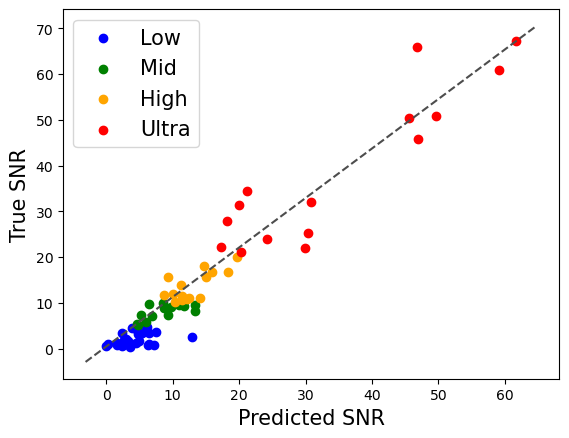

In [349]:
img_predictions = list(param_r_preds.values())
img_labels = list(param_r_labels.values())
r2 = r2_score(img_predictions, img_labels)
mape = mean_absolute_percentage_error(img_predictions, img_labels)
rmse = root_mean_squared_error(img_predictions, img_labels)
sensor_c_labels = np.array(list(param_c_labels.values()))
fig, ax = plt.subplots()
#plt.title(f"SNR Prediction: R^2 ={np.round(r2, 2)}, RMSE={np.round(rmse,2)}")
low_class_idx = np.argwhere(sensor_c_labels == 0).flatten()
mid_class_idx = np.argwhere(sensor_c_labels == 1).flatten()
hgh_class_idx = np.argwhere(sensor_c_labels == 2).flatten()
ult_class_idx = np.argwhere(sensor_c_labels == 3).flatten()

ax.scatter(np.array(img_predictions)[low_class_idx], np.array(img_labels)[low_class_idx], c = 'blue', label = 'Low')
ax.scatter(np.array(img_predictions)[mid_class_idx], np.array(img_labels)[mid_class_idx], c = 'green', label = 'Mid')
ax.scatter(np.array(img_predictions)[hgh_class_idx], np.array(img_labels)[hgh_class_idx], c = 'orange', label = 'High')
ax.scatter(np.array(img_predictions)[ult_class_idx], np.array(img_labels)[ult_class_idx], c = 'red', label = 'Ultra')

ax.set_xlabel("Predicted SNR", fontsize=15)
ax.set_ylabel("True SNR", fontsize=15)
ax.plot(ax.get_xlim(), ax.get_ylim(), ls="--", c=".3") 
plt.legend(fontsize = 15)
# plt.savefig("snr_regression_performance.pdf")

In [350]:
print(r2, rmse)

0.8927676335597357 4.43090643961488


# Load Replicated SEMs

## functions

In [179]:
base_img_path ="E:\ZnO_sensing_optimisation\Sensor-optimize-new-replicate\SEM Images"
all_file_paths = find_all_image_paths(base_img_path)

In [175]:
base_response_path ="E:\ZnO_sensing_optimisation\Sensor-optimize-new-replicate\Sensor Responses\\"
#base_response_path ="E:\ZnO_sensing_optimisation\sensor-param-opt\\new_sensor_responses\\"
dfs_full = {}
for filename in os.listdir(base_response_path):
    if filename.endswith('xlsx'):
        params = extract_params_from_filename(filename)
        df = pd.read_excel(base_response_path+filename, sheet_name=0)
        dfs_full[params[0]] = df

In [176]:
results = []
for param, signal_df in dfs_full.items():
    param_list = param.split("_")
    sol_con = param_list[0][:-1]
    current = param_list[1][:-1]
    time = param_list[2][:-1]
    
    signal = load_sheet_data(signal_df)
    cycles = find_cycles(signal)
    flat_signal, _ = remove_baseline(signal[:, 1], method = 'als')
    for c_num, (on, off) in enumerate(cycles, 1):
            if c_num == 1:
                bl_start   = max(0, on - 40)
                baseline_R = [signal[j][1] for j in range(10, bl_start) if signal[j][2] == 0]
                baseline_C = [flat_signal[j] for j in range(10, bl_start) if signal[j][2] == 0]
            else:
                baseline_C = [flat_signal[j] for j in range(on, on+40)]
            
            exp_C      = [flat_signal[j] for j in range(on, off)]
            #if not baseline_R or not exp_R:
            #    continue
            mean_conc          = sum(signal[j][2] for j in range(on, off)) / (off - on)
            R_base             = base_response(baseline_C) # baseline removed base response
            _, sigma_base      = mean_std(baseline_R) # sigma from original response
            #noise_overall, _   = estimate_noise(signal[:,1])
            R_exp              = response(exp_C)
            delta_R            = abs(R_exp - R_base)
            snr_lin = delta_R / sigma_base if sigma_base > 0 else float('inf')
            
            scaled_baseline = MinMaxScaler().fit_transform(np.array(baseline_R).reshape(-1, 1)).flatten()
            _, sigma_scaled = mean_std(scaled_baseline)
            
            results.append([sol_con, current, time, c_num, 
                            round(mean_conc, 4), round(R_base, 4), 
                            round(R_exp, 4), round(delta_R, 4), 
                            round(sigma_base, 4), round(sigma_scaled, 4),
                             round(snr_lin, 4)])

In [177]:
rep_snr_df = pd.DataFrame(results, columns=['sol_con', 'current', 'time', 'cycle_no', 'mean_conc', 'base_r', 'response_r', 'delta_r', 'sigma_base',  "sigma_scaled", 'snr_lin' ])
sensor_snr_df_rep = rep_snr_df.groupby(['sol_con', 'current', 'time']).median().reset_index()

magnification = '500x'
custom_label_rep = {}
for _, row in sensor_snr_df_rep.iterrows():
    name = str(row.sol_con)+'M-' + row.current + 'uA-' + row.time + 's-'+ magnification
    custom_label_rep[name] = float(row.snr_lin)#[row.snr, row.response_time]

custom_label_clean_rep = {}
for _, row in sensor_snr_df_rep.iterrows():
    name = str(row.sol_con)+'M-' + row.current + 'uA-' + row.time + 's'
    custom_label_clean_rep[name] = float(row.snr_lin)#[row.snr, row.response_time]

In [ ]:
custom_crop = CustomCrop(0, 0, 0, 0)
patch_size = 480
transform_img = transforms.Compose([
    custom_crop,
    SliceImageIntoPatches(patch_size=patch_size),
    #transforms.Resize((224, 224)),  # Resize all images to 224x224
    #transforms.ToTensor()           # Convert image to tensor
    
])
full_dataset = CustomClassificationDatasetWithOriginalLabel(root_dir=base_img_path, transform=transform_img, targets=custom_label_rep)
data_loader = DataLoader(full_dataset, batch_size=1, shuffle=True)

In [ ]:
save_dir_test = f"./replicate_SEM_patches"
os.makedirs(save_dir_test, exist_ok=True)
save_img_by_dataloader(data_loader, save_dir_test)

100%|██████████| 18/18 [00:30<00:00,  1.72s/it]


In [ ]:
save_dir_test = f"./replicate_SEM_patches"
rep_dataset = CustomClassificationDatasetWithOriginalLabel(root_dir=save_dir_test, transform=transforms.ToTensor(), targets=custom_label_clean)
rep_dataloader = DataLoader(rep_dataset, batch_size=40, shuffle=False)

In [ ]:
ResNetmodel.eval()
rep_C_predictions = []
rep_R_predictions = []
rep_C_labels = []
rep_R_labels = []
rep_fabParams = []
for inputs, fabParam, class_labels, snr_labels in tqdm(rep_dataloader):
    inputs = inputs.to(device).float()
    fabParam = fabParam.to(device).float()
    class_labels = class_labels.to(device).float()
    snr_labels = snr_labels.to(device).float()
    with torch.no_grad():  # No need to compute gradients during inference
        C_outputs, R_outputs = ResNetmodel(inputs)
    C_predicted = torch.argmax(torch.Tensor(np.array(C_outputs.cpu())), 1)
    rep_C_predictions.extend(C_outputs.cpu().numpy())
    rep_R_predictions.extend(R_outputs.cpu().numpy())
    rep_C_labels.extend(class_labels.cpu().numpy())
    rep_R_labels.extend(snr_labels.cpu().numpy())
    rep_fabParams.extend(fabParam.cpu().numpy())
# Convert to numpy arrays for easier handling
pred = torch.argmax(torch.Tensor(np.array(rep_C_predictions)),1)
rep_C_labels = np.array(rep_C_labels)
accuracy = accuracy_score(pred.numpy(), rep_C_labels)
mae = mean_absolute_error(np.array(rep_R_predictions), np.array(rep_R_labels))
print(accuracy, mae)

# XAI Interpretation

## Functions

In [65]:
from torchcam.utils import overlay_mask
from torchcam.methods import LayerCAM, ScoreCAM
from scipy import stats
from sklearn.metrics.pairwise import pairwise_distances
from skbio.stats.distance import permanova
import skbio
from itertools import combinations

In [66]:
def compute_mask_overlap_iou(M1: np.ndarray, M2: np.ndarray, threshold: float = 0.5) -> float:
    """
    Computes the percentage overlap (Intersection over Union) between two
    Class Activation Maps (CAMs) after binarizing them.

    Args:
        M1 (np.ndarray): The first CAM tensor (heatmap).
        M2 (np.ndarray): The second CAM tensor (heatmap).
        threshold (float): The value used to binarize the heatmaps into masks.

    Returns:
        float: The IoU score, representing the percentage overlap (0.0 to 1.0).
    """
    # 1. Binarization (Thresholding)
    # Convert heatmaps (floats) into binary masks (0s and 1s)
    mask1 = (M1 >= threshold).astype(int)
    mask2 = (M2 >= threshold).astype(int)

    # 2. Compute Intersection (logical AND)
    # Element-wise multiplication, where only (1 * 1) = 1 (overlap)
    intersection = np.sum(mask1 * mask2)
    
    # 3. Compute Union (logical OR)
    # Element-wise addition, and then clipping/capping to 1.
    # sum(M1) + sum(M2) - intersection = Union
    union = np.sum(mask1) + np.sum(mask2) - intersection

    # Handle the case where neither mask has any activated area
    if union == 0:
        return 1.0 if intersection == 0 else 0.0 # Return 1.0 (100% overlap) if both are empty

    # 4. Calculate IoU
    iou = intersection / union
    
    # Return as a percentage
    return iou

def _binarise(maps: np.ndarray, threshold: float) -> np.ndarray:
    """Threshold float saliency maps into boolean masks.

    If `maps` is already boolean it is returned unchanged. Otherwise each map
    is binarised relative to its own dynamic range, so a single global
    `threshold` (in [0, 1]) is meaningful across maps with different scales.
    """
    if maps.dtype == bool:
        return maps

    maps = maps.astype(np.float64)
    flat = maps.reshape(maps.shape[0], -1)
    lo = flat.min(axis=1, keepdims=True)
    hi = flat.max(axis=1, keepdims=True)
    rng = np.where(hi > lo, hi - lo, 1.0)
    norm = (flat - lo) / rng
    return (norm >= threshold).reshape(maps.shape)

def _iou(a: np.ndarray, b: np.ndarray) -> float:
    """Intersection-over-union of two boolean masks.

    Two empty masks are defined as perfectly overlapping (IoU = 1.0).
    """
    inter = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    if union == 0:
        return 1.0
    return float(inter) / float(union)

def getCAMMapping(method, label_force=None):
    CAM_maps = []

    for img, _, label, _ in tqdm(CAMtest_DisplayLoader):

        with method(ResNetmodel, 'layer3') as cam_extractor:
            # Preprocess your data and feed it to the model
            C_out, R_out = ResNetmodel(img.to(device))
            # Retrieve the CAM by passing the class index and the model output
            if label_force is not None:
                activation_map = cam_extractor(label_force, C_out)
            else:
                activation_map = cam_extractor(label.item(), C_out)
            CAM_maps.append(activation_map[0].cpu().numpy().squeeze())
            del activation_map

    return CAM_maps

def matrices_permanova(matrices_group_A, matrices_group_B, threshold = 0.6, metric = 'jaccard'):
    if threshold == 0:
        mask1 = np.array(matrices_group_A)
        mask2 = np.array(matrices_group_B)
    else:
        mask1 = (np.array(matrices_group_A) >= threshold).astype(int)
        mask2 = (np.array(matrices_group_B) >= threshold).astype(int)

    N_A = len(mask1)
    N_B = len(mask2)
    N_total = N_A + N_B
    matrix_shape = mask1.shape
    matrix_size_flat = matrix_shape[1] * matrix_shape[2]  # 196

    # Combine all matrices into one 3D array
    all_matrices = np.concatenate([np.array(mask1), np.array(mask2)])

    # Create the corresponding grouping vector
    grouping = ['A'] * N_A + ['B'] * N_B

    print(f"Total matrices: {all_matrices.shape[0]}")  # (192, 14, 14)

    # Flatten the 14x14 matrices into 1D vectors (length 196)
    # The data must be 2D: (n_samples, n_features)
    data_flat = all_matrices.reshape(N_total, matrix_size_flat)

    print(f"Flattened data shape: {data_flat.shape}")  # (192, 196)

    # --- 2. Calculate a Distance Matrix ---

    # Compute the distance between every matrix and every other matrix.
    # We use 'euclidean' distance, which is the Frobenius norm for matrices.
    # This creates a 192x192 matrix.
    distance_matrix = pairwise_distances(data_flat, metric = metric)
    distance_matrix = skbio.DistanceMatrix(distance_matrix)

    print(f"Distance matrix shape: {distance_matrix.shape}") # (192, 192)

    # --- 3. Run PERMANOVA ---

    # Run the test!
    # We use 999 permutations by default, which is standard.
    print("\nRunning PERMANOVA test...")
    results = permanova(distance_matrix, grouping)

    # --- 4. Interpret the Results ---
    print("\n--- PERMANOVA Results ---")
    print(results)

    # Plots image from tensor
def tensor_imshow(inp, title=None, **kwargs):
    """Imshow for Tensor."""
    #inp = inp.numpy().transpose((1, 2, 0))
    # Mean and std for ImageNet
    #mean = np.array([0.485, 0.456, 0.406])
    #std = np.array([0.229, 0.224, 0.225])
    #inp = std * inp + mean
    #inp = np.clip(inp, 0, 1)
    plt.imshow(inp, **kwargs)
    if title is not None:
        plt.title(title)

def find_active_maps_idx(CAM_maps, threshold = 1):
    active_maps_idx = []
    for i, maps in enumerate(CAM_maps):
        if maps.sum() > threshold:
            active_maps_idx.append(i)
    

    return active_maps_idx

def compute_iou_same_image(maps_0, maps_1, maps_2, maps_3, threshold=0.6):
    low_low_iou = []
    low_mid_iou = []
    low_hgh_iou = []
    low_ult_iou = []
    mid_mid_iou = []
    mid_hgh_iou = []
    mid_ult_iou = []
    hgh_hgh_iou = []
    hgh_ult_iou = []
    ult_ult_iou = []
    for map0, map1, map2, map3 in zip(maps_0, maps_1, maps_2, maps_3):
        low_low = compute_mask_overlap_iou(map0, map0, threshold=threshold)
        low_mid = compute_mask_overlap_iou(map0, map1, threshold=threshold)
        low_hgh = compute_mask_overlap_iou(map0, map2, threshold=threshold)
        low_ult = compute_mask_overlap_iou(map0, map3, threshold=threshold)
        mid_mid = compute_mask_overlap_iou(map1, map1, threshold=threshold)
        mid_hgh = compute_mask_overlap_iou(map1, map2, threshold=threshold)
        mid_ult = compute_mask_overlap_iou(map1, map3, threshold=threshold)
        hgh_hgh = compute_mask_overlap_iou(map2, map2, threshold=threshold)
        hgh_ult = compute_mask_overlap_iou(map2, map3, threshold=threshold)
        ult_ult = compute_mask_overlap_iou(map3, map3, threshold=threshold)

        low_low_iou.append(low_low)
        low_mid_iou.append(low_mid)
        low_hgh_iou.append(low_hgh)
        low_ult_iou.append(low_ult)
        mid_mid_iou.append(mid_mid)
        mid_hgh_iou.append(mid_hgh)
        mid_ult_iou.append(mid_ult)
        hgh_hgh_iou.append(hgh_hgh)
        hgh_ult_iou.append(hgh_ult)
        ult_ult_iou.append(ult_ult)

    return low_low_iou, low_mid_iou, low_hgh_iou, low_ult_iou, mid_mid_iou, mid_hgh_iou, mid_ult_iou, hgh_hgh_iou, hgh_ult_iou, ult_ult_iou

def cosine_similarity_numpy(arr_a, arr_b):
    # 1. Flatten the feature dimensions: [n, 15, 15] -> [n, 225]
    a_flat = arr_a.reshape(arr_a.shape[0], -1)
    b_flat = arr_b.reshape(arr_b.shape[0], -1)

    # 2. Compute Norms (L2 norm) along axis 1
    # keepdims=True is crucial to maintain shape [n, 1] for broadcasting
    norm_a = np.linalg.norm(a_flat, axis=1, keepdims=True)
    norm_b = np.linalg.norm(b_flat, axis=1, keepdims=True)

    # 3. Compute Cosine Similarity
    # Formula: (A . B) / (|A| * |B|)
    
    # Numerator: Matrix multiplication [n, 225] @ [225, p] -> [n, p]
    numerator = a_flat @ b_flat.T
    
    # Denominator: Outer product of norms [n, 1] @ [1, p] -> [n, p]
    denominator = norm_a @ norm_b.T
    
    # Avoid division by zero (optional safety)
    denominator[denominator == 0] = 1e-10

    return numerator / denominator

## CNN feature similarity

In [139]:
from typing import Dict, Any, Tuple
# Dictionary to store the output of intermediate layers
# Key: Layer Name (str), Value: Feature Map (Tensor)
ACTIVATION_STORAGE: Dict[str, torch.Tensor] = {}

def capture_activation(name: str) -> callable:
    """
    Creates a closure function (the hook) that captures the output (feature map) 
    of a layer during the forward pass and stores it in ACTIVATION_STORAGE.
    
    Args:
        name (str): The name to assign to the feature map in the storage dictionary.
        
    Returns:
        callable: The hook function to be registered.
    """
    # Note: A forward hook function receives: (module, input, output)
    def hook_fn(module: nn.Module, input: Tuple[torch.Tensor], output: torch.Tensor):
        # We clone the output tensor to ensure we store a snapshot, not a view 
        # that could be modified later by in-place operations.

        feature_tensor = output[0] if isinstance(output, tuple) else output
        
        ACTIVATION_STORAGE[name] = feature_tensor.clone()
    return hook_fn

In [140]:
hook_handle = target_module.register_forward_hook(capture_activation(LAYER_NAME))

train_features = []
train_class_labels = []
train_snr_labels = []
train_fabParam_list =[]

ResNetmodel.eval() # Set model to evaluation mode
    
for inputs, fabParam, class_labels, snr_labels in tqdm(train_loader):
    inputs = inputs.to(device).float()
    fabParam = fabParam.to(device).float()
    with torch.no_grad():  # No need to compute gradients during inference
        _= ResNetmodel(inputs)#ResNetmodel([inputs, fabParam])
            
        # Retrieve features from storage (output of target_feature_layer)
        if LAYER_NAME in ACTIVATION_STORAGE:
            features = ACTIVATION_STORAGE[LAYER_NAME]
            features = nn.AdaptiveAvgPool2d((1,1))(features).squeeze()
            # features = np.concatenate([features.cpu().numpy(), fabParam.cpu().numpy()], axis = -1)
            train_features.append(features.cpu().numpy())
            train_class_labels.append(class_labels.cpu().numpy())
            train_snr_labels.append(snr_labels.cpu().numpy())
            train_fabParam_list.append(fabParam.cpu().numpy())
            # Clear storage for the next batch if you want to reuse the global dict
            # For this simple example, we let the features accumulate via the list.
            
hook_handle.remove() # Clean up the hrain

100%|██████████| 578/578 [01:40<00:00,  5.76it/s]


In [141]:
 # --- Register the Hook on the Target Layer ---
# We want to capture the output of 'self.target_fc_layer'
LAYER_NAME = "layer3"
    
# 1. Get the target module (the layer object itself)
target_module = ResNetmodel.layer3
    
# 2. Register the hook function and store the handle
# The 'handle' allows us to remove the hook later
hook_handle = target_module.register_forward_hook(capture_activation(LAYER_NAME))

test_features = []
test_class_labels = []
test_snr_labels = []
test_fabParam_list = []

ResNetmodel.eval() # Set model to evaluation mode
    
for inputs, fabParam, class_labels, snr_labels in tqdm(test_loader):
    inputs = inputs.to(device).float()
    fabParam = fabParam.to(device).float()
    with torch.no_grad():  # No need to compute gradients during inference
        _= ResNetmodel(inputs)#ResNetmodel([inputs, fabParam])
            
        # Retrieve features from storage (output of target_feature_layer)
        if LAYER_NAME in ACTIVATION_STORAGE:
            features = ACTIVATION_STORAGE[LAYER_NAME]
            features = nn.AdaptiveAvgPool2d((1,1))(features).squeeze()
            #features = np.concatenate([features.cpu().numpy(), fabParam.cpu().numpy()], axis = -1)
            test_features.append(features.cpu().numpy())
            test_class_labels.append(class_labels.cpu().numpy())
            test_snr_labels.append(snr_labels.cpu().numpy())
            test_fabParam_list.append(fabParam.cpu().numpy())
            # Clear storage for the next batch if you want to reuse the global dict
            # For this simple example, we let the features accumulate via the list.
            
hook_handle.remove() # Clean up the hook
    
# Concatenate all features and labels from all batches
#features_array = np.concatenate(all_features, axis=0)
#labels_array = np.concatenate(all_labels, axis=0)

100%|██████████| 195/195 [00:22<00:00,  8.86it/s]


In [142]:
 # --- Register the Hook on the Target Layer ---
# We want to capture the output of 'self.target_fc_layer'
LAYER_NAME = "layer3"
    
# 1. Get the target module (the layer object itself)
target_module = ResNetmodel.layer3
    
# 2. Register the hook function and store the handle
# The 'handle' allows us to remove the hook later
hook_handle = target_module.register_forward_hook(capture_activation(LAYER_NAME))

rep_features = []
rep_class_labels = []
rep_snr_labels = []
rep_fabParam_list = []

ResNetmodel.eval() # Set model to evaluation mode
    
for inputs, fabParam, class_labels, snr_labels in tqdm(rep_dataloader):
    inputs = inputs.to(device).float()
    fabParam = fabParam.to(device).float()
    with torch.no_grad():  # No need to compute gradients during inference
        _= ResNetmodel(inputs)#ResNetmodel([inputs, fabParam])
            
        # Retrieve features from storage (output of target_feature_layer)
        if LAYER_NAME in ACTIVATION_STORAGE:
            features = ACTIVATION_STORAGE[LAYER_NAME]
            features = nn.AdaptiveAvgPool2d((1,1))(features).squeeze()
            #features = np.concatenate([features.cpu().numpy(), fabParam.cpu().numpy()], axis = -1)
            rep_features.append(features.cpu().numpy())
            rep_class_labels.append(class_labels.cpu().numpy())
            rep_snr_labels.append(snr_labels.cpu().numpy())
            rep_fabParam_list.append(fabParam.cpu().numpy())
            # Clear storage for the next batch if you want to reuse the global dict
            # For this simple example, we let the features accumulate via the list.
            
hook_handle.remove() # Clean up the hook
    
# Concatenate all features and labels from all batches
#features_array = np.concatenate(all_features, axis=0)
#labels_array = np.concatenate(all_labels, axis=0)

100%|██████████| 10/10 [00:02<00:00,  3.41it/s]


In [143]:
def flatten_list(input_list):
    list_flatten = []

    for i in input_list:
        for j in i:
            list_flatten.append(j)
            
    
    return list_flatten

test_features_flatten = flatten_list(test_features) 
test_class_labels_flatten = flatten_list(test_class_labels)
test_snr_labels_flatten = flatten_list(test_snr_labels)
test_fabParam_flatten = flatten_list(test_fabParam_list)

train_features_flatten = flatten_list(train_features)
train_class_labels_flatten = flatten_list(train_class_labels)
train_snr_labels_flatten = flatten_list(train_snr_labels)
train_fabParam_flatten = flatten_list(train_fabParam_list)

rep_features_flatten = flatten_list(rep_features)
rep_class_labels_flatten = flatten_list(rep_class_labels)
rep_fabParam_flatten = flatten_list(rep_fabParam_list)
rep_snr_labels_flatten = flatten_list(rep_snr_labels)

In [144]:
# Initialize and fit t-SNE
# Perplexity is a crucial parameter, often between 5 and 50.
tsne = TSNE(n_components=2, random_state=42, perplexity=30, learning_rate='auto', init='random')

# Apply t-SNE transformation
# 
tsne_results = tsne.fit_transform(np.concatenate([train_features_flatten, test_features_flatten, rep_features_flatten]))

In [145]:
snr_labels_full = np.concatenate([train_snr_labels_flatten, test_snr_labels_flatten, rep_snr_labels_flatten])
removed_outlier_idx = np.argwhere(snr_labels_full < 100).flatten()
snr_labels = snr_labels_full[removed_outlier_idx]
print(len(snr_labels))

12760


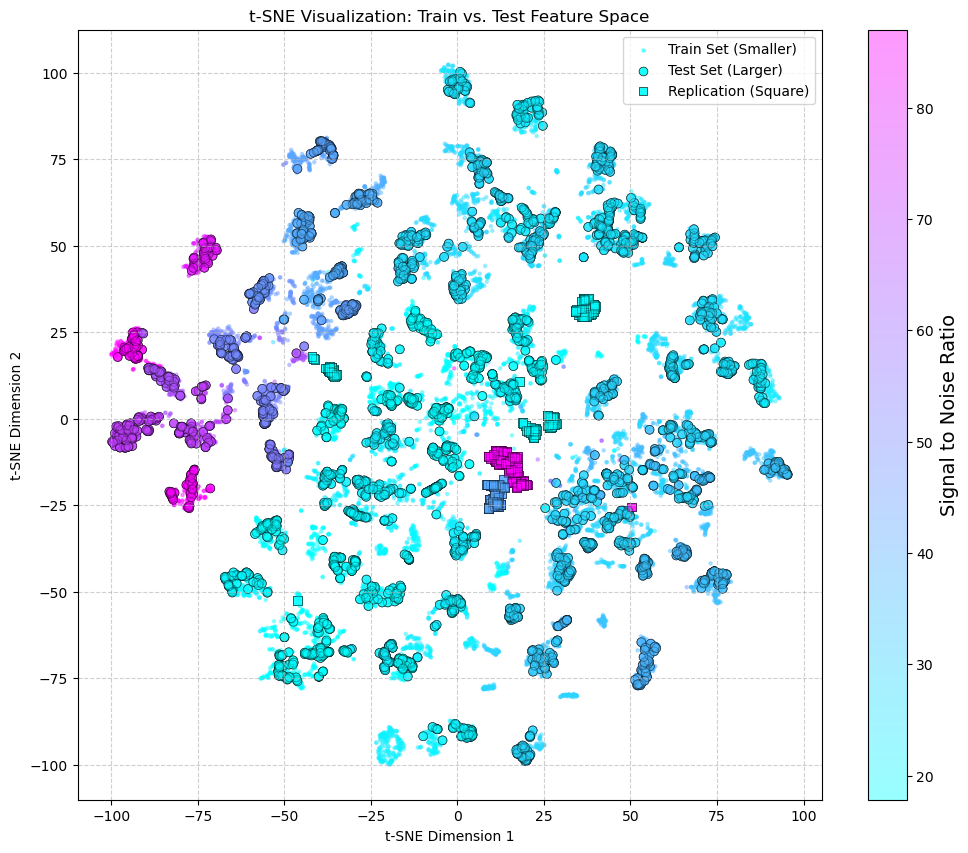

In [146]:
full_features = np.concatenate([train_features_flatten, test_features_flatten, rep_features_flatten])#[removed_outlier_idx]
set_ids = np.concatenate([np.zeros(len(train_features_flatten)), np.ones(len(test_features_flatten)), np.full(len(rep_features_flatten), 2)])[removed_outlier_idx]
labels = np.concatenate([train_class_labels_flatten, test_class_labels_flatten, rep_class_labels_flatten])#[removed_outlier_idx]
fabParams = np.concatenate([train_fabParam_flatten, test_fabParam_flatten, rep_fabParam_flatten])#[removed_outlier_idx]
tsne_results_roi = tsne_results[removed_outlier_idx]

unique_class_labels = np.unique(train_class_labels_flatten)
#class_labels_name = ['Low', 'Medium', 'High', 'Ultra High']
colormaps = [cm.cool]#[cm.Purples, cm.Blues, cm.Greens, cm.Oranges]# cm.tab10, cm.Accent, cm.Dark2, cm.Set1, cm.Set2]
# Define marker sizes
TRAIN_SIZE = 5
TEST_SIZE = 40 # Significantly larger for the test set

plt.figure(figsize=(12, 10))

for i, label in enumerate(unique_class_labels):
        # 1. Get the current class's colormap
        cmap = colormaps[i % len(colormaps)]
        
        # 2. Find indices for the current class
        class_indices_mask = labels == label
        
        # 3. Separate Train and Test indices for plotting order (Test on top)
        is_train = (set_ids == 0)# & class_indices_mask
        is_test = (set_ids == 1) #& class_indices_mask
        is_rep = (set_ids == 2)
        # --- Plot Training Data (Smaller Markers, plotted first) ---
        train_scatter = plt.scatter(
            tsne_results_roi[is_train, 0], 
            tsne_results_roi[is_train, 1], 
            c=snr_labels[is_train],            # Color gradient
            cmap=cmap,                      # Class-specific colormap
            s=TRAIN_SIZE,                   # Smaller size
            alpha=0.1,                      # More transparent
            marker='o',
            #label=f'{class_labels_name[int(label)]} (Train)'
        )
        
        # --- Plot Testing Data (Larger Markers, plotted second/on top) ---
        test_scatter = plt.scatter(
            tsne_results_roi[is_test, 0], 
            tsne_results_roi[is_test, 1], 
            c=snr_labels[is_test],             # Color gradient
            cmap=cmap,                      # Class-specific colormap
            s=TEST_SIZE,                    # Larger size
            alpha=0.4,                      # Less transparent
            marker='o',                     # Use a distinct marker shape (Diamond)
            edgecolors='k',                 # Black outline for visibility
            linewidths=0.5,
            #label=f'{class_labels_name[int(label)]}'
        )

        # Note: We plot the legend entry for the class only once (i == 0) to avoid duplication.
        # We manually add a legend entry for Test/Train markers afterwards.
        test_scatter = plt.scatter(
            tsne_results_roi[is_rep, 0], 
            tsne_results_roi[is_rep, 1], 
            c=snr_labels[is_rep],             # Color gradient
            cmap=cmap,                      # Class-specific colormap
            s=TEST_SIZE,                    # Larger size
            alpha=0.4,                      # Less transparent
            marker='s',                     # Use a distinct marker shape (Diamond)
            edgecolors='k',                 # Black outline for visibility
            linewidths=0.5,
            #label=f'{class_labels_name[int(label)]}'
        )

plt.title("t-SNE Visualization: Train vs. Test Feature Space")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
    
# Manually create legend entries for Train/Test size/marker differentiation
train_handle = plt.scatter([], [], s=TRAIN_SIZE, color='cyan', alpha=0.5, marker='o', label='Train Set (Smaller)')
test_handle = plt.scatter([], [], s=TEST_SIZE, color='cyan', alpha=0.9, marker='o', edgecolors='k', linewidths=0.5, label='Test Set (Larger)')
rep_handle = plt.scatter([], [], s=TEST_SIZE, color='cyan', alpha=0.9, marker='s', edgecolors='k', linewidths=0.5, label='Replication (Square)')
# Combine the custom handles with the automatically generated class labels
handles, labels_text = plt.gca().get_legend_handles_labels()
plt.legend(loc='best')


cbar = plt.colorbar(test_scatter)
cbar.set_label('Signal to Noise Ratio', fontsize=14)

plt.grid(True, linestyle='--', alpha=0.6)
#plt.show()
plt.savefig("tsne2.pdf")

In [ ]:
def normalizeCmap(snr):
    scaler = StandardScaler()
    scaled_snr = scaler.fit_transform(snr.reshape(1, -1))
    return scaled_snr*100

In [20]:
low_idx = np.argwhere(test_class_labels_flatten == np.int64(0))
mid_idx = np.argwhere(test_class_labels_flatten == np.int64(1))
hgh_idx = np.argwhere(test_class_labels_flatten == np.int64(2))
ult_idx = np.argwhere(test_class_labels_flatten == np.int64(3))
print(len(low_idx), len(mid_idx), len(hgh_idx), len(ult_idx))

1080 720 680 640


In [21]:
low_feature =np.array([test_features_flatten[x].squeeze() for x in low_idx.squeeze()])
med_feature =np.array([test_features_flatten[x].squeeze() for x in mid_idx.squeeze()])
hgh_feature =np.array([test_features_flatten[x].squeeze() for x in hgh_idx.squeeze()])
ult_feature =np.array([test_features_flatten[x].squeeze() for x in ult_idx.squeeze()])

In [22]:
low_low_cs = cosine_similarity_numpy(low_feature, low_feature)
low_mid_cs = cosine_similarity_numpy(low_feature, med_feature)
low_hgh_cs = cosine_similarity_numpy(low_feature, hgh_feature)
low_ult_cs = cosine_similarity_numpy(low_feature, ult_feature)
mid_mid_cs = cosine_similarity_numpy(med_feature, med_feature)
mid_hgh_cs = cosine_similarity_numpy(med_feature, hgh_feature)
mid_ult_cs = cosine_similarity_numpy(med_feature, ult_feature)
hgh_hgh_cs = cosine_similarity_numpy(hgh_feature, hgh_feature)
hgh_ult_cs = cosine_similarity_numpy(hgh_feature, ult_feature)
ult_ult_cs = cosine_similarity_numpy(ult_feature, ult_feature)

In [23]:
print("CNN Feature")
print(f'Cosine Similarity low vs. low, mean: {np.mean(low_low_cs)}, std: {np.std(low_low_cs)}')
print(f'Cosine Similarity low vs. mid, mean: {np.mean(low_mid_cs)}, std: {np.std(low_mid_cs)}')
print(f'Cosine Similarity low vs. hgh, mean: {np.mean(low_hgh_cs)}, std: {np.std(low_hgh_cs)}')
print(f'Cosine Similarity low vs. ult, mean: {np.mean(low_ult_cs)}, std: {np.std(low_ult_cs)}')
print(f'Cosine Similarity mid vs. mid, mean: {np.mean(mid_mid_cs)}, std: {np.std(mid_mid_cs)}')
print(f'Cosine Similarity mid vs. hgh, mean: {np.mean(mid_hgh_cs)}, std: {np.std(mid_hgh_cs)}')
print(f'Cosine Similarity mid vs. ult, mean: {np.mean(mid_ult_cs)}, std: {np.std(mid_ult_cs)}')
print(f'Cosine Similarity hgh vs. hgh, mean: {np.mean(hgh_hgh_cs)}, std: {np.std(hgh_hgh_cs)}')
print(f'Cosine Similarity hgh vs. ult, mean: {np.mean(hgh_ult_cs)}, std: {np.std(hgh_ult_cs)}')
print(f'Cosine Similarity ult vs. ult, mean: {np.mean(ult_ult_cs)}, std: {np.std(ult_ult_cs)}')

CNN Feature
Cosine Similarity low vs. low, mean: 0.8446727991104126, std: 0.07536353170871735
Cosine Similarity low vs. mid, mean: 0.761191725730896, std: 0.08678007870912552
Cosine Similarity low vs. hgh, mean: 0.7853502035140991, std: 0.0838170275092125
Cosine Similarity low vs. ult, mean: 0.7553815245628357, std: 0.09000902622938156
Cosine Similarity mid vs. mid, mean: 0.8662273287773132, std: 0.06565369665622711
Cosine Similarity mid vs. hgh, mean: 0.769650399684906, std: 0.07924006879329681
Cosine Similarity mid vs. ult, mean: 0.7497485876083374, std: 0.0901956781744957
Cosine Similarity hgh vs. hgh, mean: 0.900249719619751, std: 0.05692707747220993
Cosine Similarity hgh vs. ult, mean: 0.7755919098854065, std: 0.07702866941690445
Cosine Similarity ult vs. ult, mean: 0.8795520067214966, std: 0.062382426112890244


In [24]:
param_feature_std_dict = {}
unique_param_combo = np.unique(test_fabParam_flatten, axis=0).squeeze()
for param_combo in unique_param_combo:
    mask = (test_fabParam_flatten == param_combo).all(axis=1)
    img_features = np.array(test_features_flatten)[np.where(mask)[0]]
    param_feature_std_dict[str(param_combo[0])+"_"+str(param_combo[1])+"_"+str(param_combo[2])] = np.std(img_features)

In [25]:
print(f"Within image CNN feature variability:{np.array(list(param_feature_std_dict.values())).mean()} +/- {np.array(list(param_feature_std_dict.values())).std()}")

Within image CNN feature variability:0.2241576462984085 +/- 0.058779917657375336


## Image activation overlap

In [67]:
CAMtest_DisplayLoader = DataLoader(test_dataset, batch_size=1, shuffle=False)
test_imgs = []
test_label = []
test_snr = []
test_fabParam = []
for img, fabParam, label, snr in tqdm(CAMtest_DisplayLoader):
    test_imgs.append(img)
    test_fabParam.append(fabParam.numpy())
    test_label.append(label)
    test_snr.append(snr.detach().numpy())


100%|██████████| 3120/3120 [00:12<00:00, 240.83it/s]


In [68]:
LayerCAM_maps =  getCAMMapping(LayerCAM)

100%|██████████| 3120/3120 [00:46<00:00, 67.32it/s]


In [69]:
LayerCAM_maps_0 =  getCAMMapping(LayerCAM, label_force=0)
LayerCAM_maps_1 =  getCAMMapping(LayerCAM, label_force=1)
LayerCAM_maps_2 =  getCAMMapping(LayerCAM, label_force=2)
LayerCAM_maps_3 =  getCAMMapping(LayerCAM, label_force=3)

100%|██████████| 3120/3120 [00:50<00:00, 61.24it/s]


In [26]:
np.array(LayerCAM_maps).shape

(3120, 30, 30)

In [70]:
def between_category_iou(CAM_maps_0, CAM_maps_1, CAM_maps_2, CAM_maps_3, threshold):
    
    image_iou = {}
    binary_maps_0 = _binarise(np.array(CAM_maps_0), threshold)
    binary_maps_1 = _binarise(np.array(CAM_maps_1), threshold)
    binary_maps_2 = _binarise(np.array(CAM_maps_2), threshold)
    binary_maps_3 = _binarise(np.array(CAM_maps_3), threshold)
    
    iou_01 = _iou(binary_maps_0, binary_maps_1)
    iou_02 = _iou(binary_maps_0, binary_maps_2)
    iou_03 = _iou(binary_maps_0, binary_maps_3)
    iou_12 = _iou(binary_maps_1, binary_maps_2)
    iou_13 = _iou(binary_maps_1, binary_maps_3)
    iou_23 = _iou(binary_maps_2, binary_maps_3)

    image_iou = {"low_mid": iou_01,
                 "low_hgh": iou_02,
                 "low_ult": iou_03,
                 "mid_hgh": iou_12,
                 "mid_ult": iou_13,
                 "hgh_ult": iou_23}

    return image_iou

In [71]:
threshold = 0.6
unique_param_combo = np.unique(test_fabParam, axis=0).squeeze()
n_images = len(unique_param_combo)
all_ious = []
for param_combo in tqdm(unique_param_combo):
    mask = (test_fabParam == param_combo).all(axis=2)
    img_idx = np.where(mask)[0]
    low_maps = np.array(LayerCAM_maps_0)[img_idx]
    mid_maps = np.array(LayerCAM_maps_1)[img_idx]
    hgh_maps = np.array(LayerCAM_maps_2)[img_idx]
    ult_maps = np.array(LayerCAM_maps_3)[img_idx]
    img_iou = between_category_iou(low_maps, mid_maps, hgh_maps, ult_maps, threshold)
    all_ious.append(img_iou)

100%|██████████| 71/71 [00:00<00:00, 76.50it/s]


In [72]:
iou_df = pd.DataFrame(all_ious)

In [73]:
print("LayerCAM")
#print(f'IOU low vs. low, mean: {np.mean(layer_low_low_iou)}, std: {np.std(layer_low_low_iou)}')
print(f'IOU low vs. mid, mean: {iou_df.low_mid.mean()}, std: {iou_df.low_mid.std()}')
print(f'IOU low vs. hgh, mean: {iou_df.low_hgh.mean()}, std: {iou_df.low_hgh.std()}')
print(f'IOU low vs. ult, mean: {iou_df.low_ult.mean()}, std: {iou_df.low_ult.std()}')
#print(f'IOU mid vs. mid, mean: {np.mean(layer_mid_mid_iou)}, std: {np.std(layer_mid_mid_iou)}')
print(f'IOU mid vs. hgh, mean: {iou_df.mid_hgh.mean()}, std: {iou_df.mid_hgh.std()}')
print(f'IOU mid vs. ult, mean: {iou_df.mid_ult.mean()}, std: {iou_df.mid_ult.std()}')
#print(f'IOU hgh vs. hgh, mean: {np.mean(layer_hgh_hgh_iou)}, std: {np.std(layer_hgh_hgh_iou)}')
print(f'IOU hgh vs. ult, mean: {iou_df.hgh_ult.mean()}, std: {iou_df.hgh_ult.std()}')
#print(f'IOU ult vs. ult, mean: {np.mean(layer_ult_ult_iou)}, std: {np.std(layer_ult_ult_iou)}')

LayerCAM
IOU low vs. mid, mean: 0.1830664488556551, std: 0.22622996400757914
IOU low vs. hgh, mean: 0.17152028030828292, std: 0.180434322907854
IOU low vs. ult, mean: 0.08767214092321719, std: 0.0820664575320902
IOU mid vs. hgh, mean: 0.20266260141886389, std: 0.17713549947923687
IOU mid vs. ult, mean: 0.15605143399120489, std: 0.11640718853228131
IOU hgh vs. ult, mean: 0.27763534651873595, std: 0.1963313215381147


In [74]:
iou_df.mean().values.mean()

np.float64(0.17976804200265997)

In [75]:
print(f"Between Category CNN LayerCAM Map variability: {iou_df.std().values.mean()}")

Between Category CNN LayerCAM Map variability: 0.16310079233285937


In [76]:
threshold = 0.6
unique_param_combo = np.unique(test_fabParam, axis=0).squeeze()
n_images = len(unique_param_combo)
image_ious = {}
for param_combo in tqdm(unique_param_combo):
    mask = (test_fabParam == param_combo).all(axis=2)
    img_idx = np.where(mask)[0]
    n_patches = len(img_idx)
    pairs = list(combinations(range(n_patches), 2))

    attention_maps = np.array(LayerCAM_maps)[img_idx]
    ious = np.fromiter(
                (_iou(_binarise(attention_maps[a], threshold), _binarise(attention_maps[b], threshold)) for a, b in pairs),
                dtype=np.float64,
                count=len(pairs),
            )
    image_ious[str(param_combo)] = ious

100%|██████████| 71/71 [00:01<00:00, 39.16it/s]


In [77]:
mean_iou = []
std_iou = []
for iou in image_ious.values():
    mean_iou.append(iou.mean())
    std_iou.append(iou.std())

In [78]:
print(f"Within image CNN LayerCAM Map variability:{np.mean(std_iou)}")

Within image CNN LayerCAM Map variability:0.025041813670286527


In [79]:
print(f"CNN LayerCAM Map variability ratio: {iou_df.std().values.mean() / np.mean(std_iou)}")

CNN LayerCAM Map variability ratio: 6.513138164844159


In [80]:
np.mean(mean_iou)

np.float64(0.07733366600753075)

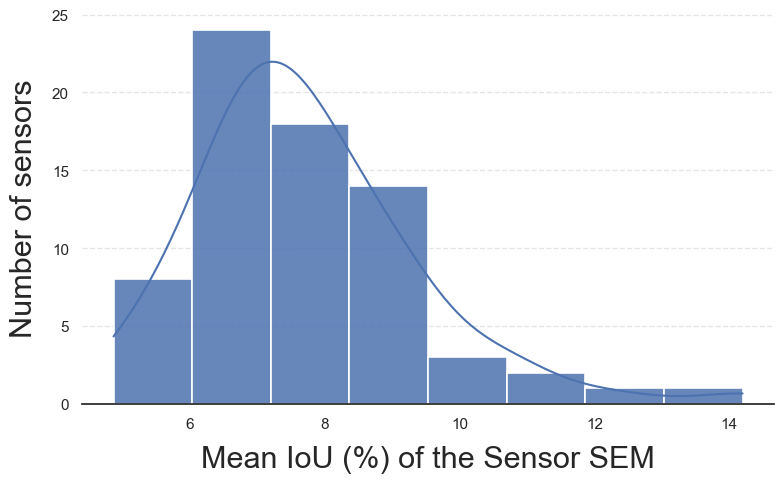

In [93]:
# 1. Set a clean, modern style baseline
sns.set_theme(style="white", palette="muted")

# Create figure
fig, ax = plt.subplots(figsize=(8, 5))

# 2. Plot histogram with subtle borders and a KDE curve
sns.histplot(
    data=np.array(mean_iou)*100,
    kde=True,  # Adds smooth line
    bins=8,  # Optimal bin count
    color="#4C72B0",  # Soft slate blue
    edgecolor="white",  # Crisp gap between bars
    linewidth=1.2,
    alpha=0.85,  # Slight transparency
    ax=ax,
)

# 3. Clean up the container (Despining removes harsh borders)
sns.despine(left=True, bottom=False)

# 4. Enhance typography and layout
#ax.set_title("Distribution of IoU", fontsize=16, pad=15, weight="bold")
ax.set_xlabel("Mean IoU (%) of the Sensor SEM", fontsize=22, labelpad=10)
ax.set_ylabel("Number of sensors", fontsize=22, labelpad=10)
ax.grid(axis="y", linestyle="--", alpha=0.5)  # Subtle horizontal grid only

plt.tight_layout()
plt.savefig("mean_iou_per_sensor.pdf")
plt.show()

In [111]:
print(np.where(np.array(mean_iou) < 0.075)[0].shape)
print(np.where(np.array(mean_iou) > 0.1)[0].shape)

(36,)
(6,)


In [92]:
all_image_ious = []
for ious in image_ious.values():
    for iou in ious:
        all_image_ious.append(np.mean(iou))

In [124]:
# Plots image from tensor
def tensor_imshow(inp, title=None, **kwargs):
    """Imshow for Tensor."""
    #inp = inp.numpy().transpose((1, 2, 0))
    # Mean and std for ImageNet
    #mean = np.array([0.485, 0.456, 0.406])
    #std = np.array([0.229, 0.224, 0.225])
    #inp = std * inp + mean
    #inp = np.clip(inp, 0, 1)
    plt.imshow(inp, **kwargs)
    if title is not None:
        plt.title(title)

In [146]:
mask = (test_fabParam == np.array([0.2, 3000, 30])).all(axis=2)
img_idx = np.where(mask)[0]

In [ ]:
for i in range(len(img_idx)):
    result_lcam = overlay_mask(to_pil_image(test_imgs[img_idx[i]].squeeze()), to_pil_image(LayerCAM_maps[img_idx[i]].squeeze(), mode='F'), alpha=0.5)
    plt.axis('off')
    #plt.title('Grad CAM explanation')
    tensor_imshow(result_lcam)
    plt.tight_layout()
    plt.show()